In [34]:
# ============================================================================
# SECTION 1: IMPORT LIBRARIES
# ============================================================================
import numpy as np  # Numerical computations and array operations
import pandas as pd  # Data manipulation and analysis
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt  # Missing import for visualization

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

In [35]:
# ============================================================================
# ENCODING CATEGORICAL VARIABLES
# ============================================================================

df = pd.read_csv("../data/processed/iris_clean.csv")

In [36]:
# ============================================================================
# ENCODING CATEGORICAL VARIABLES
# ============================================================================

# Create a copy if you want to preserve original
df_encoded = df.copy()

# Encode the target variable
le = LabelEncoder()
df_encoded['class_encoded'] = le.fit_transform(df_encoded['class'])

In [ ]:
# ============================================================================
# DEFINE VARIABLES
# ============================================================================

# Features (independent variables)
X = df_encoded[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

# Target (dependent variable) - use the encoded version
y = df_encoded["class_encoded"]

Class mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}


Class mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}


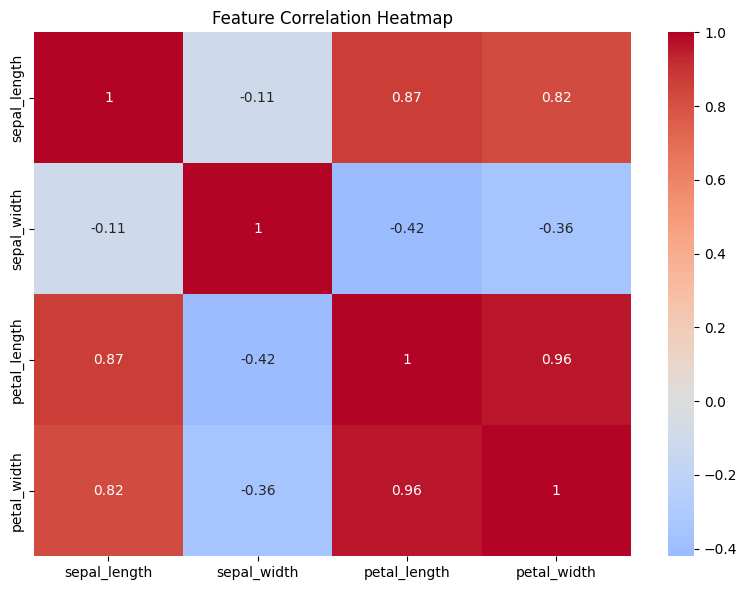

In [38]:
# ============================================================================
# VISUALIZATION AND ANALYSIS
# ============================================================================

# Check the class mapping
original_classes = df['class'].unique()
encoded_classes = le.classes_
class_mapping = dict(zip(encoded_classes, range(len(encoded_classes))))
print("Class mapping:", class_mapping)

# Create correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()  # Display the plot

In [39]:
# ============================================================================
# SAVE PROCESSED DATA
# ============================================================================

# Save features
X.to_csv("../data/processed/X.csv", index=False)

# Save target - FIXED: using 'y' not 'y_encoded'
pd.DataFrame(y, columns=["class_encoded"]).to_csv(
    "../data/processed/y.csv", index=False
)